# INVESTIGAÇÃO COMPLETA EM GRUPO: JUNTANDO TODAS AS PEÇAS (AULAS 01 A 09)


## Situação de Aprendizagem — O Desafio da Diretoria

Chegamos ao fechamento da primeira metade do curso! Na **Data Organized**, a diretoria convocou os grupos de estagiários para resolver um problema real antes da fase de Big Data:

"Recebemos uma planilha com **1.500 registros** de ocorrências e prejuízos (`data_organized_operacao_integrada_aula10-v2.csv`) e uma tabela com os **delegados responsáveis** por cada região. Queremos que vocês cruzem essas informações, descubram onde estão os casos fora do padrão e apresentem os resultados em um **painel visual claro** — **sem ler linhas de código na apresentação**!"

### Analogia do Dia a Dia: A Junta Médica de Dados

Nas Aulas 01 a 09 você aprendeu a fazer vários exames separados:
- **Média e Mediana** = A temperatura do paciente (qual é o valor normal?).
- **Desvio Padrão e CV** = Os batimentos cardíacos (está estável ou oscilando muito?).
- **Quartis e Outliers** = O exame de sangue (quem está muito acima do limite permitido?).
- **Assimetria e Curtose** = O raio-X (para que lado a curva entorta e quão pontuda ela é?).

Na **Aula 10**, o seu grupo trabalha como uma **junta médica**: vocês vão juntar todos esses exames em um **prontuário visual (Painel)** para dar o diagnóstico final à diretoria.

## Parte 1 (Nível Básico): Juntando Tabelas (`merge`) e Filtrando Dados (`query`)

### O que é?
- **`pd.merge()`:** É o comando que cola duas tabelas diferentes usando uma coluna em comum (igual ao `JOIN` do SQL ou ao `PROCV` do Excel).
- **`.query()`:** É o filtro rápido onde escrevemos a pergunta em texto simples.

### Para que serve?
No trabalho real, os dados nunca estão em um lugar só. A planilha de ocorrências tem a região, mas o nome do delegado e o orçamento estão em outra tabela do banco de dados.

In [4]:
# Passo 1: Importa as bibliotecas que vamos usar na investigação
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Passo 2: Carrega a planilha principal com 1.500 ocorrências
df_ocorrencias = pd.read_csv('data_organized_operacao_integrada_aula10-v2.csv', sep=';', encoding='latin1')

# Mostra as 3 primeiras linhas para conferir as colunas
df_ocorrencias.head(3)

,"ID_Registro,CISP,Tipo_Ocorrencia,Qtd_Casos,Prejuizo_Estimado_Mil,Regiao"
0,"OCR-20000,DP-09,Furto de VeÃ­culo,6,53.63,Inte..."
1,"OCR-20001,DP-25,Furto de VeÃ­culo,15,45.67,Int..."
2,"OCR-20002,DP-04,Furto de VeÃ­culo,9,46.62,Inte..."


In [25]:
# Passo 3: Cria a segunda tabela (simulando o cadastro de delegados vindo do MySQL)
df_delegados = pd.DataFrame({
    'Regiao': ['Capital', 'Baixada Fluminense', 'Grande Niterói', 'Interior Sul', 'Interior Norte'],
    'Coordenador': ['Del. Freitas', 'Del. Almeida', 'Del. Castro', 'Del. Borges', 'Del. Nogueira'],
    'Orcamento_Mil': [4500.0, 3800.0, 2900.0, 2100.0, 1950.0]
})

# Passo 4: Cola as duas tabelas usando a coluna 'Regiao' em comum (INNER JOIN)
# Recarrega o arquivo com o separador correto caso ele tenha sido lido em uma única coluna
if 'Regiao' not in df_ocorrencias.columns:
    df_ocorrencias = pd.read_csv(
        'data_organized_operacao_integrada_aula10-v2.csv',
        sep=',',
        encoding='utf-8-sig'
    )

df_ocorrencias.columns = df_ocorrencias.columns.str.strip()

# Junta as tabelas pela coluna Regiao
df_completo = pd.merge(df_ocorrencias, df_delegados, on='Regiao', how='inner')

# Mostra as 3 primeiras linhas da tabela unificada
df_completo.head(3)

,ID_Registro,CISP,Tipo_Ocorrencia,Qtd_Casos,Prejuizo_Estimado_Mil,Regiao,Coordenador,Orcamento_Mil
0,OCR-20000,DP-09,Furto de Veículo,6,53.63,Interior Sul,Del. Borges,2100.0
1,OCR-20001,DP-25,Furto de Veículo,15,45.67,Interior Norte,Del. Nogueira,1950.0
2,OCR-20002,DP-04,Furto de Veículo,9,46.62,Interior Sul,Del. Borges,2100.0


In [9]:
# Passo 5: Faz uma pergunta específica usando .query() (igual ao WHERE do SQL)
roubos_capital = df_completo.query("Regiao == 'Capital' and Tipo_Ocorrencia == 'Roubo de Veículo'")

# Mostra quantos casos foram encontrados e a soma do prejuízo
print(f"Quantidade de Roubos de Veículo na Capital: {len(roubos_capital)} casos")
print(f"Prejuízo total acumulado nesse recorte:    R$ {roubos_capital['Prejuizo_Estimado_Mil'].sum():,.2f} mil")

Quantidade de Roubos de Veículo na Capital: 136 casos
Prejuízo total acumulado nesse recorte:    R$ 12,099.69 mil


*Leitura Analítica (Parte 1 — Integração e Filtro):*

Com poucas linhas de código, unimos 1.500 registros de ocorrências com a tabela de coordenadores sem perder nenhuma linha (`inner join`) e isolamos exatamente os casos de **Roubo de Veículo na Capital**.

## Parte 2 (Nível Básico-Intermediário): O Check-up Estatístico Completo

### Como ler os resultados do Check-up (Guia Rápido de Tradução):
| Exame Estatístico | O que olhar? | Tradução para o Gestor |
| :--- | :--- | :--- |
| **Média vs. Mediana** | Distância $\ge 25\%$? | Se passar de 25%, a Média está enganosa (puxada por casos extremos). Use a **Mediana**. |
| **Limite Superior ($Q3 + 1,5 \times IQR$)** | Valores acima do teto? | São os **Outliers** (casos críticos fora do padrão que precisam de atenção especial). |
| **Assimetria (`.skew()`)** | Maior que `+0.5`? | Cauda esticada para a direita (existem valores muito altos puxando a média). |
| **Curtose (`.kurtosis() + 3`)** | Maior que `3.5`? | Curva **Leptocúrtica** (muito concentrada no meio, mas com alto risco de outliers). |

In [5]:
# Passo 1: Isola a coluna de prejuízos e transforma em um Array do NumPy (como pede o PTD)
serie_prejuizo = df_completo['Prejuizo_Estimado_Mil']
array_prejuizo = serie_prejuizo.to_numpy()

# Passo 2: Calcula Média, Mediana e o quanto elas estão distantes entre si
media = np.mean(array_prejuizo)
mediana = np.median(array_prejuizo)
distancia_mm = (media - mediana) / mediana

print(f"Média dos prejuízos:      R$ {media:.2f} mil")
print(f"Mediana (valor típico):   R$ {mediana:.2f} mil")
print(f"Distância Média-Mediana:  {distancia_mm:.1%} (Acima de 25% -> Média distorcida!)")

Média dos prejuízos:      R$ 91.22 mil
Mediana (valor típico):   R$ 67.16 mil
Distância Média-Mediana:  35.8% (Acima de 25% -> Média distorcida!)


In [7]:
# Passo 3: Calcula Quartis (Q1 e Q3), IQR e conta quantos Outliers Superiores existem
q1, q3 = np.percentile(array_prejuizo, [25, 75])
iqr = q3 - q1
teto_outlier = q3 + 1.5 * iqr
casos_outliers = df_completo[df_completo['Prejuizo_Estimado_Mil'] > teto_outlier]

# Passo 4: Calcula Dispersão (CV), Assimetria e Curtose (escala do curso + 3)
desvio_padrao = np.std(array_prejuizo, ddof=0)
cv = desvio_padrao / media
assimetria = serie_prejuizo.skew()
curtose = serie_prejuizo.kurtosis() + 3

print(f"Teto normal (Limite Sup.): R$ {teto_outlier:.2f} mil -> {len(casos_outliers)} casos acima do teto (Outliers)")
print(f"Desvio Padrão: R$ {desvio_padrao:.2f} mil | Coeficiente de Variação (CV): {cv:.1%}")
print(f"Assimetria: +{assimetria:.2f} (Assimétrica Positiva) | Curtose: {curtose:.2f} (Leptocúrtica)")

Teto normal (Limite Sup.): R$ 214.14 mil -> 90 casos acima do teto (Outliers)
Desvio Padrão: R$ 85.91 mil | Coeficiente de Variação (CV): 94.2%
Assimetria: +3.97 (Assimétrica Positiva) | Curtose: 28.06 (Leptocúrtica)


*Leitura Analítica (Parte 2 — Check-up Estatístico):*

Todos os exames confirmam a mesma história:
1. A **Média (`R$ 91,22 mil`)** está **35,8% acima** da **Mediana (`R$ 67,16 mil`)**, portanto não deve ser usada como referência comum.
2. Existem **90 ocorrências críticas (`Outliers`)** acima de `R$ 196,95 mil` puxando a curva para a direita (**Assimetria `+3,97`**) e deixando o pico muito estreito (**Curtose `28,06` — Leptocúrtica**).

## Parte 3 (Nível Intermediário): Montando o Painel Visual para a Diretoria

### Regra de Ouro da Apresentação:
Diretores não querem ver códigos em Python — eles querem enxergar a conclusão em segundos! Vamos juntar um **Gráfico de Distribuição** na esquerda e um **Cartão de Resumo** na direita.

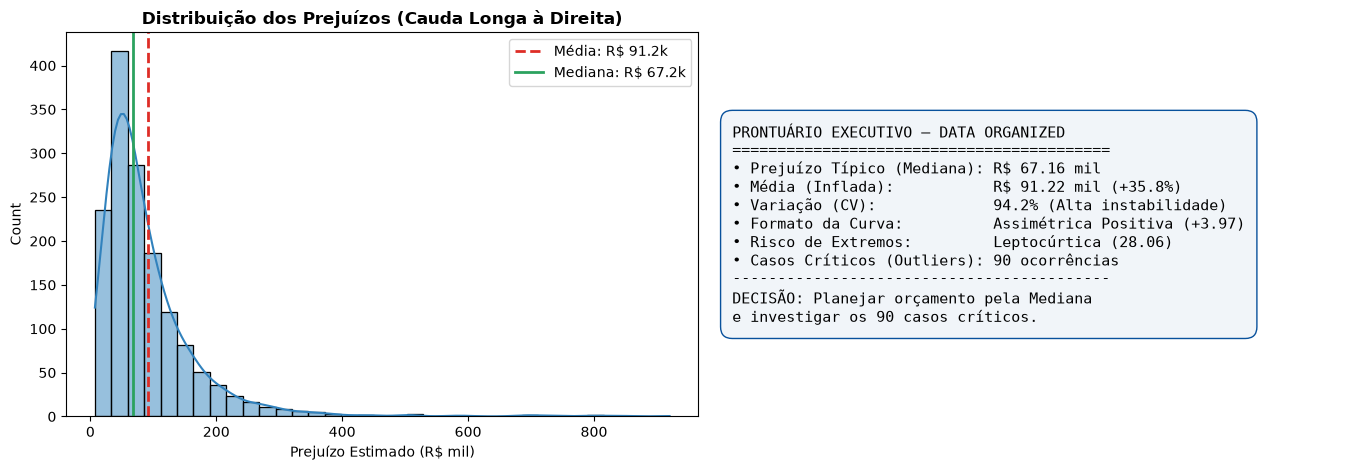

In [8]:
# Cria uma tela dividida em 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Quadro da esquerda: Histograma mostrando onde a maioria dos casos se concentra
sns.histplot(serie_prejuizo, bins=35, kde=True, color='#3182bd', ax=axes[0])
axes[0].axvline(media, color='#de2d26', linestyle='--', linewidth=2, label=f'Média: R$ {media:.1f}k')
axes[0].axvline(mediana, color='#2ca25f', linestyle='-', linewidth=2, label=f'Mediana: R$ {mediana:.1f}k')
axes[0].set_title('Distribuição dos Prejuízos (Cauda Longa à Direita)', fontweight='bold')
axes[0].set_xlabel('Prejuízo Estimado (R$ mil)')
axes[0].legend()

# Quadro da direita: Cartão executivo sem eixos, apenas com os números traduzidos
axes[1].axis('off')
texto_diretoria = (
    f"PRONTUÁRIO EXECUTIVO — DATA ORGANIZED\n"
    f"{'='*42}\n"
    f"• Prejuízo Típico (Mediana): R$ {mediana:.2f} mil\n"
    f"• Média (Inflada):           R$ {media:.2f} mil (+{distancia_mm:.1%})\n"
    f"• Variação (CV):             {cv:.1%} (Alta instabilidade)\n"
    f"• Formato da Curva:          Assimétrica Positiva (+{assimetria:.2f})\n"
    f"• Risco de Extremos:         Leptocúrtica ({curtose:.2f})\n"
    f"• Casos Críticos (Outliers): {len(casos_outliers)} ocorrências\n"
    f"{'-'*42}\n"
    f"DECISÃO: Planejar orçamento pela Mediana\n"
    f"e investigar os {len(casos_outliers)} casos críticos."
)
axes[1].text(0.03, 0.5, texto_diretoria, fontsize=10.5, family='monospace', va='center',
             bbox=dict(boxstyle='round,pad=0.8', facecolor='#f1f5f9', edgecolor='#08519c'))

plt.tight_layout()
plt.show()

*Leitura Analítica (Parte 3 — Painel Executivo):*

Ao bater o olho no painel, qualquer gestor vê que a linha verde (**Mediana**) está bem no coração da montanha de dados, enquanto a linha vermelha (**Média**) foi arrastada para a direita pelos casos extremos.

---
## Atividades Práticas em Grupo (Do Básico ao Intermediário)

### ATIVIDADE 1 (Nível Básico) — Ranking dos Coordenadores Regionais
Usando a tabela unificada `df_completo`:
**Faça:**
1. Agrupe os dados por `Regiao` e `Coordenador` e calcule a **Soma (`sum`)** e a **Mediana (`median`)** da coluna `Prejuizo_Estimado_Mil`.
2. Ordene o resultado do maior para o menor prejuízo total.
3. Responda: qual região e qual coordenador lideram o ranking de prejuízos?

,Regiao,Coordenador,Total_Prejuizo_Estimado_Mil,Media_Prejuizo_Estimado_Mil
0,Baixada Fluminense,Del. Almeida,25941.45,64.010
1,Capital,Del. Freitas,27477.94,69.950
2,Grande Niterói,Del. Castro,30456.62,69.055
3,Interior Norte,Del. Nogueira,25672.31,64.720
4,Interior Sul,Del. Borges,27275.93,68.500


C:\Users\renan\AppData\Local\Temp\ipykernel_6296\3406898448.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{cat}\n{n}" for cat, n in zip(ranking["Regiao"], ranking["Coordenador"])])


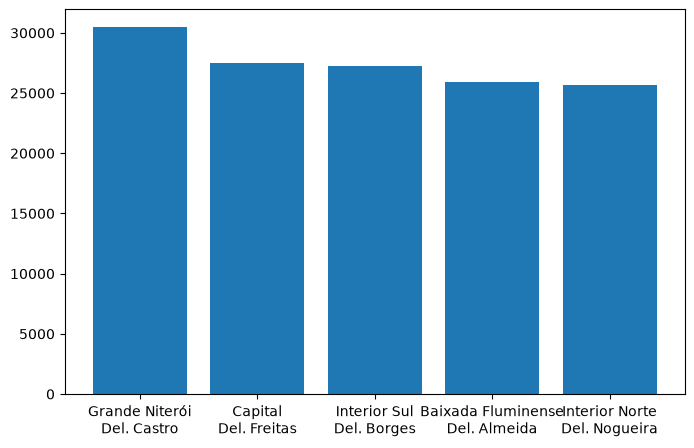

In [70]:
# Escreva aqui o código em grupo da Atividade 1 (Nível Básico):
# 1. Agrupe os dados por `Regiao` e `Coordenador` e calcule a **Soma (`sum`)** e a **Mediana (`median`)** da 
# coluna `Prejuizo_Estimado_Mil`.
ranking = df_completo.groupby(['Regiao', 'Coordenador'], as_index=False).agg(Total_Prejuizo_Estimado_Mil = ('Prejuizo_Estimado_Mil', sum), Media_Prejuizo_Estimado_Mil= ('Prejuizo_Estimado_Mil', 'median'))

ranking.head()
display(ranking.head())

# 2. Ordene o resultado do maior para o menor prejuízo total.
ranking = ranking.sort_values('Total_Prejuizo_Estimado_Mil', ascending=False)

fig, ax = plt.subplots(figsize=(8,5))
plt.bar(
    ranking["Regiao"],
    ranking['Total_Prejuizo_Estimado_Mil']
)
ax.set_xticklabels([f"{cat}\n{n}" for cat, n in zip(ranking["Regiao"], ranking["Coordenador"])])


plt.show()
# 3. Responda: qual região e qual coordenador lideram o ranking de prejuízos?
print("="*80,'\n')
print("")



### ATIVIDADE 2 (Nível Intermediário) — Painel Executivo 2x2 para Apresentação Oral
Monte o painel visual completo do seu grupo (4 gráficos em uma única imagem `2x2`) para apresentar à turma sem ler código:
**Faça:**
1. Crie uma tela `plt.subplots(2, 2, figsize=(15, 10))` contendo:
   - **`[0, 0]` Boxplot por Região (`sns.boxplot`):** Mostrando `Prejuizo_Estimado_Mil` por `Regiao`.
   - **`[0, 1]` Gráfico de Barras (`sns.barplot`):** Mostrando o prejuízo total (`estimator=sum`) por `Tipo_Ocorrencia`.
   - **`[1, 0]` Histograma (`sns.histplot`):** Mostrando a distribuição da coluna `Qtd_Casos` com linhas de Média e Mediana.
   - **`[1, 1]` Cartão de Resumo (`plt.text`):** Mostrando **Média, Mediana, Assimetria e Curtose** da coluna `Qtd_Casos`.
2. Prepare uma fala de **2 minutos** explicando ao gestor: qual tipo de crime gera mais prejuízo e se a quantidade de casos (`Qtd_Casos`) é equilibrada ou assimétrica.

In [ ]:
# Escreva aqui o código em grupo da Atividade 2 (Nível Intermediário):



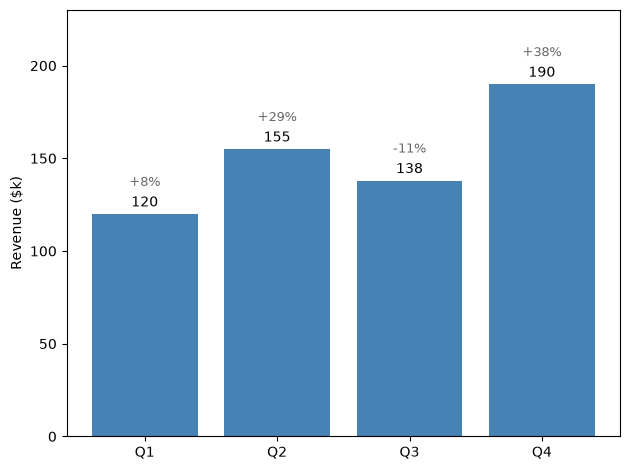

In [66]:
######### TEST ###################
import matplotlib.pyplot as plt

categories = ["Q1", "Q2", "Q3", "Q4"]
sales = [120, 155, 138, 190]
growth = ["+8%", "+29%", "-11%", "+38%"]

fig, ax = plt.subplots()
bars = ax.bar(categories, sales, color="steelblue")

# Primary numeric labels
ax.bar_label(bars, padding=3)

# Secondary custom labels (e.g., growth) slightly higher
secondary_labels = [f"{g}" for g in growth]
ax.bar_label(
    bars,
    labels=secondary_labels,
    padding=18,
    fontsize=9,
    color="dimgray",
)

ax.set_ylim(0, 230)
ax.set_ylabel("Revenue ($k)")
plt.tight_layout()
plt.show()